In [ ]:
# Parámetros a configurar:
import os
experiment_name = "command16"
task_name = "Command16"
cfg_dir = "C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_20/grid_hiperparametros/cfg_files"
path_resultados = "C:/Users/Teresa/Documents/GitHub/navsim/tmp/tmpTeresa/resultados_grid_command_v20"
path_resultados_ev2 = "C:/Users/Teresa/Documents/GitHub/navsim/tmp/tmpTeresa/resultados_env20_ev2"
isaaclab_bat = "C:/Users/Teresa/Desktop/RuralData/IsaacLab/IsaacLab/isaaclab.bat"
train_script = "C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/rl_v5_1_0/rsl_rl/train.py"
id_task = f"Isaac-{task_name}-Aerotaxi-RANDOM" # luego se le añade el número de task con el guión (Isaac-Command2-Aerotaxi-RANDOM-34)
play_script = "C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/rl_v5_1_0/rsl_rl/play.py"
num_iter = "4001"
num_steps_per_env = 128
powershell_script = os.path.join(cfg_dir, "run_all.ps1")

# Recuerda iniciar en el init todos los experimentos
test_seed = 1001


In [3]:
import random
import os


os.makedirs(cfg_dir, exist_ok=True)
os.makedirs(path_resultados, exist_ok=True)

param_options = {
    "init_noise_std": [0.1, 0.2, 0.5, 0.8, 1.0],
    "actor_hidden_dims": [[64, 64], [128, 128], [256, 256], [128, 64]],
    "critic_hidden_dims": [[64, 64], [128, 128], [256, 256]],
    "activation": ["relu", "tanh", "elu", "gelu"],
    "value_loss_coef": [0.5, 1.0, 2.0],
    "clip_param": [0.1, 0.2, 0.3],
    "entropy_coef": [0.0, 0.001, 0.01, 0.05],
    "num_learning_epochs": [4, 8, 12],
    "num_mini_batches": [2, 4, 8],
    "learning_rate": [5e-05, 1e-4, 3e-4, 1e-3, 3e-3],
    "gamma": [0.95, 0.98, 0.99],
    "lam": [0.90, 0.95, 0.97],
    "max_grad_norm": [0.5, 1.0, 2.0],
    "desired_kl": [0.005, 0.008, 0.01, 0.02],
}

num_trials = 35  
random.seed(19)  

cfg_files = []

for i in range(num_trials):
    run_name = f"ppo_random_{experiment_name}_{i+1}"
    sampled = {k: random.choice(v) for k, v in param_options.items()}

    # Convertir listas a string
    actor_dims = sampled["actor_hidden_dims"]
    critic_dims = sampled["critic_hidden_dims"]

    cfg_content = f"""
from isaaclab.utils import configclass
from isaaclab_rl.rsl_rl import RslRlOnPolicyRunnerCfg, RslRlPpoActorCriticCfg, RslRlPpoAlgorithmCfg

@configclass
class {task_name}PPORunnerCfg(RslRlOnPolicyRunnerCfg):
    num_steps_per_env = {num_steps_per_env} 
    max_iterations = {num_iter}
    save_interval = 100
    experiment_name = "{experiment_name}"
    run_name = "{run_name}"
    resume = False
    empirical_normalization = True
    csv_path_metrics = "{path_resultados}"
    callbacks = True
    policy = RslRlPpoActorCriticCfg(
        init_noise_std={sampled['init_noise_std']},
        actor_hidden_dims={actor_dims},
        critic_hidden_dims={critic_dims},
        activation="{sampled['activation']}",
    )
    algorithm = RslRlPpoAlgorithmCfg(
        value_loss_coef={sampled['value_loss_coef']},
        use_clipped_value_loss=True,
        clip_param={sampled['clip_param']},
        entropy_coef={sampled['entropy_coef']},
        num_learning_epochs={sampled['num_learning_epochs']},
        num_mini_batches={sampled['num_mini_batches']},
        learning_rate={sampled['learning_rate']},
        schedule="adaptive",
        gamma={sampled['gamma']},
        lam={sampled['lam']},
        desired_kl={sampled['desired_kl']},
        max_grad_norm={sampled['max_grad_norm']},
    )
"""
    cfg_path = os.path.join(cfg_dir, f"{run_name}_cfg.py")
    with open(cfg_path, "w") as f:
        f.write(cfg_content.strip())
    cfg_files.append((run_name, cfg_path))

# Crear archivo PowerShell para ejecutar todas las configuraciones
powershell_script = os.path.join(cfg_dir, "run_all.ps1")

num_envs =  [64, 128, 512, 1024, 2048, 4096, 8196] #número de entornos para train (paralelizados)

with open(powershell_script, "w") as f:
    f.write("$ErrorActionPreference = 'Stop'\n\n")
    j = 0
    for run_name, cfg_path in cfg_files:
        # Convertir path a módulo Python (reemplazar / y .py)
        num_envs_i = 8196
        module_path = cfg_path.replace("/", ".").replace("\\", ".").replace(".py", "")
        f.write(f'Write-Host "Ejecutando {run_name}"\n')
        f.write(f'& "{isaaclab_bat}" -p "{train_script}" --task {id_task}-{j+1} --num_envs {num_envs_i} --headless \n\n')
        j += 1
print("Archivos de configuración generados y script PowerShell listo en:", powershell_script)

Archivos de configuración generados y script PowerShell listo en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_all.ps1


In [7]:
# !powershell -ExecutionPolicy Bypass -File "{powershell_script}"
import subprocess
import sys

powershell_script_path = powershell_script 

print(f"Iniciando ejecución de: {powershell_script_path}\n")


process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

try:
    for line in process.stdout:
        print(line, end="")
        sys.stdout.flush()  
except KeyboardInterrupt:
    process.kill()
    print("\nEntrenamiento cancelado por el usuario.")

process.wait()
print("\n--- Todos los experimentos han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_all.ps1

Ejecutando ppo_random_command15_1
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261103_173250.log
2026-11-03T16:32:50Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-03T16:32:51Z s] [Warning] [carb] Acquiring non optional plugin interface which is not listed as dependency: [omni::p

``Análisis de los datos``

In [3]:
import csv
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

seed = 42
n=5

df_results_grid_actions = pd.read_csv(path_resultados+"/resultados_grid_PPO.csv")

In [4]:
def get_group(value):
    if f"_{experiment_name}" in value:
        return task_name

df_results_grid_actions["tarea"] = df_results_grid_actions["id_run_name"].apply(get_group)

In [5]:
df_copy = df_results_grid_actions.copy()
df_results_grid_actions.sample(n, random_state=seed)

,id_run_name,iteration,reward,max_reward,std_reward,num_envs_train,mean_Episode_Reward/rew_action_rate,mean_Episode_Reward/rew_ang_vel_stability4,mean_Episode_Reward/rew_attitude_stability2,mean_Episode_Reward/rew_heading,mean_Episode_Reward/rew_pos2,mean_Episode_Reward/rew_track_vel3,mean_Episode_Termination/bad_attitude,mean_Episode_Termination/below_min_altitude,mean_Episode_Termination/safety_shutdown,mean_Episode_Termination/time_out,mean_Metrics/vel_command/pos_mse,mean_Metrics/vel_command/vel_mse,mean_Metrics/vel_command/yaw_abs,tarea
460,ppo_random_command15_32,100,52.620347,246.334061,24.489581,8196,-8.315515e-03,0.180803,0.274574,0.304800,0.184919,1.088992,0.303312,0.691930,0.0,0.004758,70.871754,25.754499,1.325388,Command15
73,ppo_random_command15_6,700,372.902304,391.030914,9.089671,8196,-5.068396e-02,0.962373,1.916465,2.597241,1.731200,7.763517,0.000000,0.002196,0.0,0.997804,0.000000,0.000000,0.000000,Command15
231,ppo_random_command15_16,500,26.802616,67.622650,11.100142,8196,-4.670778e-07,0.109225,0.160129,0.176571,0.139843,0.469029,0.391071,0.608929,0.0,0.000000,43.827257,34.004341,1.459124,Command15
175,ppo_random_command15_13,1700,375.922924,392.285278,10.604324,8196,-7.370528e-02,0.961371,1.916643,2.660536,1.773887,7.794979,0.000336,0.001380,0.0,0.998283,0.048403,0.012290,0.000300,Command15
237,ppo_random_command15_16,1100,26.299444,62.302559,10.854937,8196,-4.759422e-07,0.108696,0.160093,0.173537,0.139797,0.472393,0.372230,0.627770,0.0,0.000000,45.312339,33.835340,1.482058,Command15


In [6]:
df_results_grid_actions.set_index(['tarea','id_run_name'],inplace=True)
top5 = (
    df_results_grid_actions.groupby(level="tarea")
      .apply(lambda g: g.sort_values("reward", ascending=False).head(5))
)

top5.index = top5.index.droplevel(0)

top5

iteration      reward  max_reward  \
tarea     id_run_name                                                  
Command15 ppo_random_command15_4        1100  382.327923  395.418793   
          ppo_random_command15_4        1600  381.759349  395.608734   
          ppo_random_command15_4        1000  380.674165  394.189850   
          ppo_random_command15_11       1300  380.574089  393.286407   
          ppo_random_command15_11       1400  380.321484  392.074646   

                                   std_reward  num_envs_train  \
tarea     id_run_name                                           
Command15 ppo_random_command15_4     6.610087            8196   
          ppo_random_command15_4     7.041185            8196   
          ppo_random_command15_4     6.833665            8196   
          ppo_random_command15_11    7.010709            8196   
          ppo_random_command15_11    6.391387            8196   

                                   mean_Episode_Reward/rew_action_rate  \
tarea     id_run_name                                                    
Command15 ppo_random_command15_4                             -0.000426   
          ppo_random_command15_4                             -0.000473   
          ppo_random_command15_4                             -0.000422   
          ppo_random_command15_11                            -0.071720   
          ppo_random_command15_11                            -0.072957   

                                   mean_Episode_Reward/rew_ang_vel_stability4  \
tarea     id_run_name                                                           
Command15 ppo_random_command15_4                                     0.970879   
          ppo_random_command15_4                                     0.969935   
          ppo_random_command15_4                                     0.970123   
          ppo_random_command15_11                                    0.965102   
          ppo_random_command15_11                                    0.964225   

                                   mean_Episode_Reward/rew_attitude_stability2  \
tarea     id_run_name                                                            
Command15 ppo_random_command15_4                                      1.917273   
          ppo_random_command15_4                                      1.918515   
          ppo_random_command15_4                                      1.917814   
          ppo_random_command15_11                                     1.927177   
          ppo_random_command15_11                                     1.926596   

                                   mean_Episode_Reward/rew_heading  \
tarea     id_run_name                                                
Command15 ppo_random_command15_4                          2.758779   
          ppo_random_command15_4                          2.760626   
          ppo_random_command15_4                          2.749545   
          ppo_random_command15_11                         2.731163   
          ppo_random_command15_11                         2.734588   

                                   mean_Episode_Reward/rew_pos2  \
tarea     id_run_name                                             
Command15 ppo_random_command15_4                       1.862340   
          ppo_random_command15_4                       1.833715   
          ppo_random_command15_4                       1.809246   
          ppo_random_command15_11                      1.853299   
          ppo_random_command15_11                      1.844494   

                                   mean_Episode_Reward/rew_track_vel3  \
tarea     id_run_name                                                   
Command15 ppo_random_command15_4                             7.780650   
          ppo_random_command15_4                             7.786647   
          ppo_random_command15_4                             7.775850   
          ppo_random_command15_11                            7.813921   
          ppo

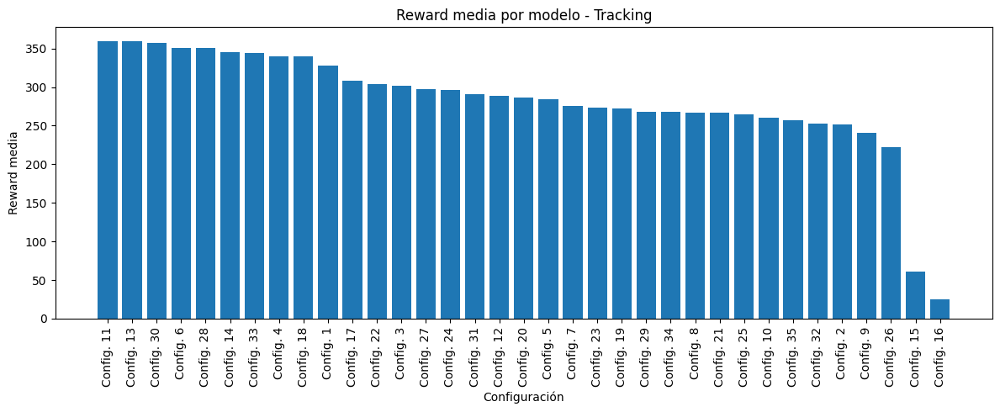

In [7]:
mean_rewards = df_results_grid_actions.groupby(["tarea", "id_run_name"])["reward"].mean()

for tarea, subdf in mean_rewards.groupby(level="tarea"):
    plt.figure(figsize=(12,5))

    plot_df = subdf.reset_index()
    plot_df = plot_df.sort_values("reward", ascending=False)
    
   
    plot_df["config_label"] = "Config. " + plot_df["id_run_name"].str.split('_').str[-1]
    
    plt.bar(plot_df["config_label"], plot_df["reward"])
    plt.title(f"Reward media por modelo - Tracking")
    plt.xlabel("Configuración")
    plt.ylabel("Reward media")
    plt.xticks(rotation=90) 
    plt.tight_layout()
    plt.show()

In [8]:
df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv",index_col='id_run_name')
top5_models = df_callbacks.nlargest(5,columns="reward")
top5_models

,iteration,reward,max_reward,std_reward,num_envs_train,mean_Episode_Reward/rew_action_rate,mean_Episode_Reward/rew_ang_vel_stability4,mean_Episode_Reward/rew_attitude_stability2,mean_Episode_Reward/rew_heading,mean_Episode_Reward/rew_pos2,mean_Episode_Reward/rew_track_vel3,mean_Episode_Termination/bad_attitude,mean_Episode_Termination/below_min_altitude,mean_Episode_Termination/safety_shutdown,mean_Episode_Termination/time_out,mean_Metrics/vel_command/pos_mse,mean_Metrics/vel_command/vel_mse,mean_Metrics/vel_command/yaw_abs
id_run_name,,,,,,,,,,,,,,,,,,
ppo_random_command15_4,1105,381.931565,396.109833,12.550378,8196,-0.000429,0.970231,1.916829,2.756958,1.860775,7.774610,0.000000,0.000249,0.0,0.999751,0.014142,0.010909,0.001956
ppo_random_command15_11,1358,380.625990,392.815704,6.711895,8196,-0.073300,0.965709,1.927262,2.740512,1.852930,7.819447,0.000000,0.000244,0.0,0.999756,0.000000,0.000000,0.000000
ppo_random_command15_6,1559,378.773371,394.406769,14.804499,8196,-0.053306,0.965096,1.920073,2.678020,1.837301,7.791090,0.000710,0.001086,0.0,0.998204,0.197788,0.045631,0.006180
ppo_random_command15_30,1804,378.172847,393.697601,9.593147,8196,-0.049087,0.968699,1.925200,2.680605,1.804315,7.798328,0.000000,0.000366,0.0,0.999634,0.000000,0.000000,0.000000
ppo_random_command15_14,1301,378.074787,394.297241,7.924367,8196,-0.048516,0.966437,1.922817,2.689423,1.793932,7.812622,0.000122,0.000195,0.0,0.999683,0.000000,0.000000,0.000000


Graficamos cómo fue el entrenamiento para los 5 mejores modelos según los callbacks:

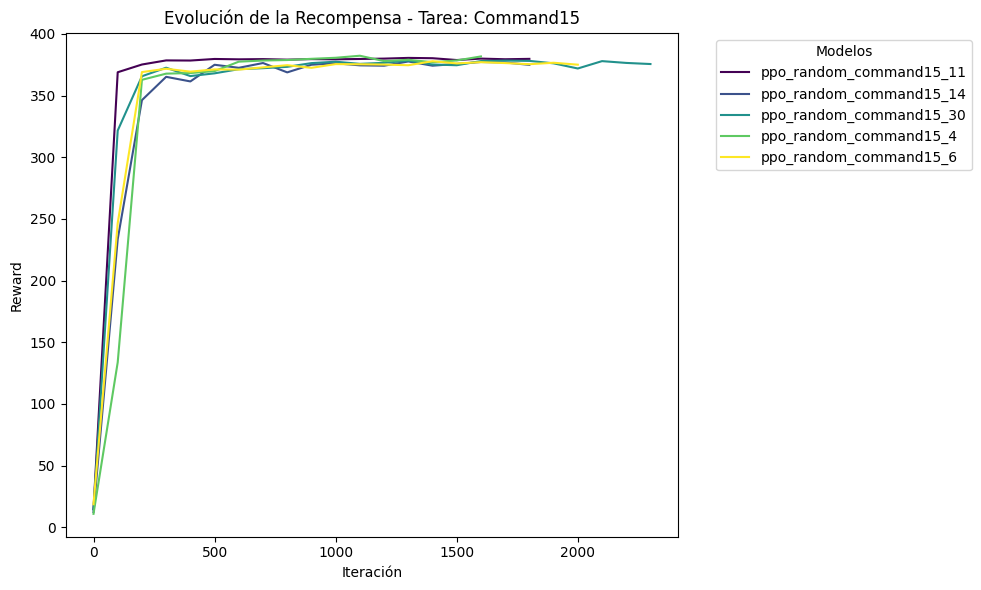

In [9]:
import matplotlib.pyplot as plt
import numpy as np

df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv",index_col='id_run_name')
top5_models = df_callbacks.nlargest(5,columns="reward")
top5_reset = top5_models.reset_index()
top5_reset["tarea"] = top5_reset["id_run_name"].apply(get_group)


df_copy_reset = df_copy.reset_index()

merged_df = pd.merge(df_copy_reset, top5_reset[['tarea', 'id_run_name']], on=['tarea', 'id_run_name'], how='inner')

colors = plt.cm.viridis(np.linspace(0, 1, len(merged_df['id_run_name'].unique())))

for tarea, task_df in merged_df.groupby('tarea'):
    plt.figure(figsize=(10, 6))
    
    
    for i, (run_name, subdf) in enumerate(task_df.groupby('id_run_name')):

        plt.plot(subdf['iteration'], subdf['reward'], label=run_name, color=colors[i])
    
    plt.xlabel('Iteración')
    plt.ylabel('Reward')
    plt.title(f'Evolución de la Recompensa - Tarea: {tarea}')
    plt.legend(title="Modelos", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()



C:/Users/Teresa/Desktop/RuralData/IsaacLab/IsaacLab/isaaclab.bat -p C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/rl_v5_1_0/rsl_rl/play.py --task Isaac-Command13-Aerotaxi-RANDOM-12 --num_envs 256 --checkpoint C:/Users/Teresa/Documents/GitHub/navsim/tmp/tmpTeresa/resultados_grid_command_v17/best_model_ppo_random_command13_12_4096.pt

### Top 5 por métricas

--- TABLA COMPLETA DE SCORES (TRAIN) ---


,Modelo,Score Global (%),Tracking (%),Seguridad (%),Estabilidad (%),Suavidad (%),Robustez (%)
0,ppo_random_command15_4,98.64,100.00,99.98,96.24,97.32,96.71
1,ppo_random_command15_21,97.68,100.00,98.76,94.56,98.60,92.21
2,ppo_random_command15_2,97.63,99.95,99.74,96.00,91.00,94.10
3,ppo_random_command15_31,97.30,100.00,97.74,95.29,97.52,90.57
4,ppo_random_command15_12,96.30,99.25,98.95,94.99,87.00,91.20
5,ppo_random_command15_22,94.26,97.92,99.37,95.59,67.62,92.65
6,ppo_random_command15_7,94.15,96.16,96.34,93.17,92.61,85.11
7,ppo_random_command15_27,93.97,95.56,96.24,93.21,94.98,83.20
8,ppo_random_command15_20,93.37,96.98,93.99,92.19,94.24,80.69
9,ppo_random_command15_10,93.20,98.30,97.47,95.02,66.55,87.68


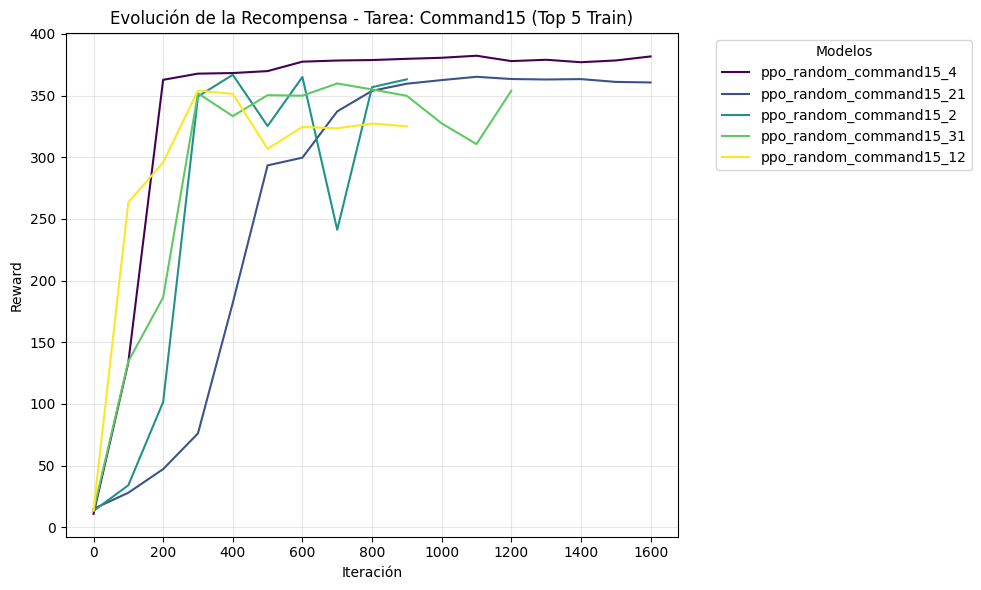

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar métricas de ENTRENAMIENTO

df_train = pd.read_csv(path_resultados + "/reward_best_models.csv")


# 2. Calcular métricas compuestas
MAX_POS = 1.5 
MAX_VEL = 7.0   
MAX_HEAD = 2.5

MAX_TRACKING_TOTAL = MAX_POS + MAX_VEL + MAX_HEAD # = 11.0

def deshacer_exponencial(recompensa_obtenida, peso_maximo):
    """Solo se aplica a recompensas gaussianas (exp) para linealizar el error"""
    ratio = (recompensa_obtenida.clip(lower=0, upper=peso_maximo) / peso_maximo)
    return np.sqrt(ratio) * peso_maximo



df_train['stability_score'] = (
    df_train['mean_Episode_Reward/rew_attitude_stability2'] +
    df_train['mean_Episode_Reward/rew_ang_vel_stability4']
)

df_train['tracking_score'] = (
    deshacer_exponencial(df_train['mean_Episode_Reward/rew_pos2'], MAX_POS) +
    df_train['mean_Episode_Reward/rew_track_vel3'].clip(upper=MAX_VEL) +
    df_train['mean_Episode_Reward/rew_heading'].clip(upper=MAX_HEAD)
)

df_train['smoothness_score'] = -df_train['mean_Episode_Reward/rew_action_rate']

df_train['failure_rate'] = (
    df_train['mean_Episode_Termination/below_min_altitude'] +
    df_train['mean_Episode_Termination/bad_attitude'] +
    df_train['mean_Episode_Termination/safety_shutdown']
)
df_train['success_rate'] = 1 - df_train['failure_rate']
df_train['cv_train'] = df_train['std_reward'] / df_train['reward']


# 3. Normalizar a porcentajes [0, 100]
def normalize_pct(x, xmin, xmax, invert=False):
    x_norm = (x - xmin) / (xmax - xmin)
    x_norm = np.clip(x_norm, 0, 1)
    if invert:
        x_norm = 1 - x_norm
    return x_norm * 100

df_train["stability_pct"] = normalize_pct(df_train["stability_score"], 0.0, 3.0)
df_train["tracking_pct"] = normalize_pct(df_train["tracking_score"], 0.0, MAX_TRACKING_TOTAL)
df_train["smoothness_pct"] = normalize_pct(df_train["smoothness_score"], 0.0, 0.016, invert=True)
df_train["success_pct"] = normalize_pct(df_train["success_rate"], 0.0, 1.0)
df_train["robustness_pct"] = normalize_pct(df_train["cv_train"], 0.0, 1.0, invert=True) # NUEVO

# 4. Calcular el Global Score
df_train["global_score"] = (
    0.35 * df_train["tracking_pct"] +
    0.25 * df_train["success_pct"] +
    0.20 * df_train["stability_pct"] +
    0.10 * df_train["robustness_pct"] +
    0.10 * df_train["smoothness_pct"]
)


# 5. Generar la Tabla Completa (Todos los modelos)
columnas_interes = [
    'id_run_name', 'global_score', 'tracking_pct', 
    'success_pct', 'stability_pct', 'smoothness_pct', 'robustness_pct'
]


df_tabla_scores = df_train[columnas_interes].copy()
df_tabla_scores = df_tabla_scores.sort_values(by='global_score', ascending=False).reset_index(drop=True)
df_tabla_scores = df_tabla_scores.round(2)


df_tabla_scores.columns = [
    'Modelo', 'Score Global (%)', 'Tracking (%)', 
    'Seguridad (%)', 'Estabilidad (%)', 'Suavidad (%)', 'Robustez (%)'
]

print("--- TABLA COMPLETA DE SCORES (TRAIN) ---")
display(df_tabla_scores) 

# 6. Extraer el Top 5 y Graficar
top5_model_names = df_tabla_scores['Modelo'].head(5).tolist()

df_copy_reset = df_copy.reset_index()

merged_df = df_copy_reset[df_copy_reset['id_run_name'].isin(top5_model_names)].copy()

if 'tarea' not in merged_df.columns:
    merged_df['tarea'] = merged_df['id_run_name'].apply(get_group)

colors = plt.cm.viridis(np.linspace(0, 1, len(top5_model_names)))

for tarea, task_df in merged_df.groupby('tarea'):
    plt.figure(figsize=(10, 6))
    for i, run_name in enumerate(top5_model_names):
        subdf = task_df[task_df['id_run_name'] == run_name]
        if not subdf.empty:
            plt.plot(subdf['iteration'], subdf['reward'], label=run_name, color=colors[i])
    
    plt.xlabel('Iteración')
    plt.ylabel('Reward')
    plt.title(f'Evolución de la Recompensa - Tarea: {tarea} (Top 5 Train)')
    plt.legend(title="Modelos", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [32]:
import os
df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv",index_col='id_run_name')

powershell_script_test_4 = os.path.join(cfg_dir, "run_tests_4.ps1")

with open(powershell_script_test_4, "w") as f:
    f.write("$ErrorActionPreference = 'Stop'\n\n")
    
    for run_id, row in df_callbacks.iterrows():
        experiment_number = run_id.split('_')[-1]
        checkpoint_path = f"{path_resultados}/best_model_{run_id}_{int(row['num_envs_train'])}.pt"
        f.write(f'Write-Host "Ejecutando Test final para Experimento {experiment_number}..."\n')
        f.write(f'& "{isaaclab_bat}" -p "{play_script}" '
                f'--task {id_task}-{experiment_number} '
                f'--num_envs 1024 '
                f' --headless '
                f'--seed {test_seed} '
                f'--checkpoint "{checkpoint_path}"\n\n')
        
print(f"Script de test generado en: {powershell_script_test_4}")


Script de test generado en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_4.ps1


In [33]:
# !powershell -ExecutionPolicy Bypass -File "{powershell_script}"
import subprocess
import sys

powershell_script_path = powershell_script_test_4 

print(f"Iniciando ejecución de: {powershell_script_path}\n")

process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, # Redirigimos errores a la salida estándar para verlos
    text=True,
    bufsize=1
)


try:
    for line in process.stdout:
        print(line, end="") 
        sys.stdout.flush()   
except KeyboardInterrupt:
    process.kill()
    print("\nEntrenamiento cancelado por el usuario.")

process.wait()
print("\n--- Todos los experimentos de test han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_4.ps1

Ejecutando Test final para Experimento 1...
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261106_173046.log
2026-11-06T16:30:46Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-06T16:30:46Z s] [Warning] [carb] Acquiring non optional plugin interface which is not listed as depend

In [18]:
import os
df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv",index_col='id_run_name')

powershell_script_test_5 = os.path.join(cfg_dir, "run_tests_5.ps1")

with open(powershell_script_test_5, "w") as f:
    f.write("$ErrorActionPreference = 'Stop'\n\n")
    
    for run_id, row in df_callbacks.iterrows():
        experiment_number = run_id.split('_')[-1]
        checkpoint_path = f"{path_resultados}/best_model_{run_id}_{int(row['num_envs_train'])}.pt"
        f.write(f'Write-Host "Ejecutando Test final para Experimento {experiment_number}..."\n')
        f.write(f'& "{isaaclab_bat}" -p "{play_script}" '
                f'--task {id_task}-{experiment_number} '
                f'--num_envs 256 '
                f' --headless '
                f'--seed {test_seed} '
                f'--checkpoint "{checkpoint_path}"\n\n')
        
print(f"Script de test generado en: {powershell_script_test_5}")


Script de test generado en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_5.ps1


In [19]:
# !powershell -ExecutionPolicy Bypass -File "{powershell_script}"
import subprocess
import sys

powershell_script_path = powershell_script_test_5 

print(f"Iniciando ejecución de: {powershell_script_path}\n")
process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, 
    text=True,
    bufsize=1
)

try:
    for line in process.stdout:
        print(line, end="") 
        sys.stdout.flush()   
except KeyboardInterrupt:
    process.kill()
    print("\nEntrenamiento cancelado por el usuario.")

process.wait()
print("\n--- Todos los experimentos de test han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_5.ps1

Ejecutando Test final para Experimento 1...
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261106_163621.log
2026-11-06T15:36:21Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-06T15:36:22Z s] [Warning] [carb] Acquiring non optional plugin interface which is not listed as depend

In [20]:
import os
df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv",index_col='id_run_name')

powershell_script_test_6 = os.path.join(cfg_dir, "run_tests_6.ps1")

with open(powershell_script_test_6, "w") as f:
    f.write("$ErrorActionPreference = 'Stop'\n\n")
    
    for run_id, row in df_callbacks.iterrows():
       
        experiment_number = run_id.split('_')[-1]
        checkpoint_path = f"{path_resultados}/best_model_{run_id}_{int(row['num_envs_train'])}.pt"
        f.write(f'Write-Host "Ejecutando Test final para Experimento {experiment_number}..."\n')
        f.write(f'& "{isaaclab_bat}" -p "{play_script}" '
                f'--task {id_task}-{experiment_number} '
                f'--num_envs 8196 '
                f' --headless '
                f'--seed {test_seed} '
                f'--checkpoint "{checkpoint_path}"\n\n')
        
print(f"Script de test generado en: {powershell_script_test_6}")


Script de test generado en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_6.ps1


In [21]:
# !powershell -ExecutionPolicy Bypass -File "{powershell_script}"
import subprocess
import sys

powershell_script_path = powershell_script_test_6 

print(f"Iniciando ejecución de: {powershell_script_path}\n")

process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, 
    text=True,
    bufsize=1
)

try:
    for line in process.stdout:
        print(line, end="") 
        sys.stdout.flush()
except KeyboardInterrupt:
    process.kill()
    print("\nEntrenamiento cancelado por el usuario.")

process.wait()
print("\n--- Todos los experimentos de test han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_6.ps1

Ejecutando Test final para Experimento 1...
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261106_165754.log
2026-11-06T15:57:54Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-06T15:57:55Z s] [Warning] [carb] Acquiring non optional plugin interface which is not listed as depend

In [11]:
df_rewards_play = pd.read_csv(path_resultados+'/rewards_play_PPO.csv')

In [12]:
import pandas as pd

df_train = df_callbacks.copy()
if df_train.index.name == 'id_run_name':
    df_train = df_train.reset_index()

df_train = df_train.rename(columns={
    'reward': 'reward_train',
    'max_reward': 'max_reward_train',
    'std_reward': 'std_train'
})

df_test = df_rewards_play.copy()

df_test = pd.read_csv(path_resultados+'/rewards_play_PPO.csv')
df_test = df_test.rename(columns={
    'reward': 'reward_test',
    'max_reward': 'max_reward_test',
    'std': 'std_test'
})

df_final = pd.merge(
    df_train[['id_run_name', 'num_envs_train', 'reward_train', 'max_reward_train', 'std_train', 'iteration']], 
    df_test[['id_run_name', 'num_envs_test', 'reward_test', 'max_reward_test', 'std_test', 'checkpoint']], 
    on='id_run_name', 
    how='inner'
)

column_order = [
    'id_run_name',
    'num_envs_train',
    'num_envs_test',
    'reward_train', 'reward_test', 
    'max_reward_train', 'max_reward_test', 
    'std_train', 'std_test',
    'iteration'
]
df_final = df_final[column_order]

df_final = df_final.sort_values(by='id_run_name', ascending=False)

In [13]:
df_rewards_play = df_final.sort_values(by="id_run_name",ascending=False)
df_rewards_play = df_rewards_play.reset_index().drop(columns='index')

df_final = df_rewards_play.copy()

df_final['diff_rw_test_train'] = df_final['reward_test'] - df_final['reward_train']

df_final['diferencia(%)'] = (df_final['diff_rw_test_train'] / df_final['reward_train'].abs()) * 100

df_final['diferencia(%)'] = df_final['diferencia(%)'].apply(lambda x: f"{x:+.2f}%")

df_final[df_final['num_envs_test'] != 1].sort_values(by='reward_test',ascending=False).reset_index().drop(columns="index").head(10)

,id_run_name,num_envs_train,num_envs_test,reward_train,reward_test,max_reward_train,max_reward_test,std_train,std_test,iteration,diff_rw_test_train,diferencia(%)
0,ppo_random_command15_11,8196,1024,380.625990,382.599243,392.815704,394.529968,6.711895,6.290760,1358,1.973253,+0.52%
1,ppo_random_command15_11,8196,8196,380.625990,382.564148,392.815704,394.996002,6.711895,8.294268,1358,1.938158,+0.51%
2,ppo_random_command15_4,8196,1024,381.931565,382.182800,396.109833,395.812317,12.550378,6.573827,1105,0.251235,+0.07%
3,ppo_random_command15_11,8196,256,380.625990,382.100189,392.815704,393.794495,6.711895,6.377007,1358,1.474199,+0.39%
4,ppo_random_command15_4,8196,8196,381.931565,382.080627,396.109833,395.704346,12.550378,9.853617,1105,0.149062,+0.04%
5,ppo_random_command15_4,8196,256,381.931565,381.771912,396.109833,395.895264,12.550378,6.932920,1105,-0.159654,-0.04%
6,ppo_random_command15_33,8196,8196,377.497274,381.542358,394.973145,397.340302,13.528588,14.060472,835,4.045085,+1.07%
7,ppo_random_command15_33,8196,1024,377.497274,381.453064,394.973145,396.969849,13.528588,12.959060,835,3.955790,+1.05%
8,ppo_random_command15_33,8196,256,377.497274,381.437103,394.973145,396.977783,13.528588,7.609634,835,3.939830,+1.04%
9,ppo_random_command15_6,8196,8196,378.773371,381.068176,394.406769,396.447876,14.804499,17.173714,1559,2.294806,+0.61%


In [14]:
import pandas as pd

# 1. Filtrar experimentos válidos (sin num_envs_test == 1)

df_eval = (
    df_final[df_final['num_envs_test'] != 1]
    .sort_values(by='std_test', ascending=True)
    .reset_index(drop=True)
)

# 2. Seleccionar columnas necesarias del CSV original

reward_cols = [
    'id_run_name',
    'num_envs_test',
    'mean_Episode_Reward/rew_attitude_stability2',
    'mean_Episode_Reward/rew_ang_vel_stability4',
    'mean_Episode_Reward/rew_pos2',
    'mean_Episode_Reward/rew_action_rate',
    'mean_Episode_Reward/rew_heading',
    'mean_Episode_Reward/rew_track_vel3',
    'mean_Episode_Termination/below_min_altitude',
    'mean_Episode_Termination/bad_attitude',
    'mean_Episode_Termination/safety_shutdown'
]

df_metrics = pd.read_csv(path_resultados+'/rewards_play_PPO.csv')

# 3. Crear métricas compuestas

# Estabilidad actitudinal
df_metrics['stability_score'] = (
    df_metrics['mean_Episode_Reward/rew_attitude_stability2'] +
    df_metrics['mean_Episode_Reward/rew_ang_vel_stability4']
)

# Calidad de seguimiento
df_metrics['tracking_score'] = (
    deshacer_exponencial(df_metrics['mean_Episode_Reward/rew_pos2'], MAX_POS) +
    df_metrics['mean_Episode_Reward/rew_track_vel3'].clip(upper=MAX_VEL) +
    df_metrics['mean_Episode_Reward/rew_heading'].clip(upper=MAX_HEAD)
)

# Suavidad del control
# (como rew_action_rate es penalización negativa)
df_metrics['smoothness_score'] = (
    -df_metrics['mean_Episode_Reward/rew_action_rate']
)

# Tasa de fallo
df_metrics['failure_rate'] = (
    df_metrics['mean_Episode_Termination/below_min_altitude'] +
    df_metrics['mean_Episode_Termination/bad_attitude'] +
    df_metrics['mean_Episode_Termination/safety_shutdown']
)

# Tasa de éxito
df_metrics['success_rate'] = 1 - df_metrics['failure_rate']

# 4. Coeficiente de variación (robustez)

df_eval['cv_test'] = df_eval['std_test'] / df_eval['reward_test']

# 5. Merge con resultados finales

df_result = df_eval.merge(
    df_metrics[
        [
            'id_run_name',
            'num_envs_test',
            'stability_score',
            'tracking_score',
            'smoothness_score',
            'success_rate'
        ]
    ],
    on=['id_run_name', 'num_envs_test'],
    how='left'
)

# 6. Ordenar por mejor reward y menor fallo

df_result = df_result.sort_values(
    by=['reward_test', 'success_rate'],
    ascending=[False, True]
).reset_index(drop=True)

df_plot = df_result.copy()

def normalize(x, xmin, xmax, invert=False):
    x_norm = (x - xmin) / (xmax - xmin)
    x_norm = np.clip(x_norm, 0, 1)

    if invert:
        x_norm = 1 - x_norm

    return x_norm


# Escalado interpretable [0,1]

df_plot["stability_scaled"] = normalize(
    df_plot["stability_score"],
    xmin=0.0,
    xmax=3.0
)

df_plot["tracking_scaled"] = normalize(
    df_plot["tracking_score"],
    xmin=0.0,
    xmax=MAX_TRACKING_TOTAL
)

df_plot["smoothness_scaled"] = normalize(
    df_plot["smoothness_score"],
    xmin=0.0,
    xmax=0.016,
    invert=True
)


df_plot["success_scaled"] = normalize(
    df_plot["success_rate"],
    xmin=0.0,
    xmax=1.0
)

df_plot["robustness_scaled"] = normalize(
    df_plot["cv_test"],
    xmin=0.0,
    xmax=1.0,
    invert=True
)


scaled_cols = [
    "stability_scaled",
    "tracking_scaled",
    "smoothness_scaled",
    "success_scaled",
    "robustness_scaled"
]

for col in scaled_cols:
    df_plot[col.replace("_scaled", "_pct")] = df_plot[col] * 100

df_plot

,id_run_name,num_envs_train,num_envs_test,reward_train,reward_test,max_reward_train,max_reward_test,std_train,std_test,iteration,...,stability_scaled,tracking_scaled,smoothness_scaled,success_scaled,robustness_scaled,stability_pct,tracking_pct,smoothness_pct,success_pct,robustness_pct
0,ppo_random_command15_11,8196,1024,380.625990,382.599243,392.815704,394.529968,6.711895,6.290760,1358,...,0.968924,1.000000,0.000000,1.000000,0.983558,96.892448,100.000000,0.000000,100.000000,98.355784
1,ppo_random_command15_11,8196,8196,380.625990,382.564148,392.815704,394.996002,6.711895,8.294268,1358,...,0.968907,1.000000,0.000000,0.999756,0.978319,96.890728,100.000000,0.000000,99.975598,97.831928
2,ppo_random_command15_4,8196,1024,381.931565,382.182800,396.109833,395.812317,12.550378,6.573827,1105,...,0.965683,1.000000,0.992253,1.000000,0.982799,96.568330,100.000000,99.225289,100.000000,98.279926
3,ppo_random_command15_11,8196,256,380.625990,382.100189,392.815704,393.794495,6.711895,6.377007,1358,...,0.967710,1.000000,0.000000,1.000000,0.983311,96.771032,100.000000,0.000000,100.000000,98.331064
4,ppo_random_command15_4,8196,8196,381.931565,382.080627,396.109833,395.704346,12.550378,9.853617,1105,...,0.965293,1.000000,0.992230,0.999512,0.974211,96.529259,100.000000,99.222976,99.951196,97.421064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,ppo_random_command15_15,8196,8196,66.019836,64.688484,210.651398,238.575119,35.000429,34.160370,1335,...,0.195800,0.213588,0.999875,0.000000,0.471925,19.580013,21.358769,99.987460,0.000000,47.192502
101,ppo_random_command15_15,8196,256,66.019836,62.131229,210.651398,169.811371,35.000429,34.006626,1335,...,0.190929,0.205474,0.999876,0.000000,0.452665,19.092942,20.547376,99.987609,0.000000,45.266452
102,ppo_random_command15_16,8196,8196,26.829331,26.290859,66.231323,89.865601,11.459207,10.930933,836,...,0.089951,0.100017,0.999987,0.000000,0.584231,8.995051,10.001685,99.998696,0.000000,58.423067
103,ppo_random_command15_16,8196,1024,26.829331,26.195555,66.231323,61.383728,11.459207,10.551437,836,...,0.089698,0.099793,0.999987,0.000000,0.597205,8.969779,9.979274,99.998701,0.000000,59.720504


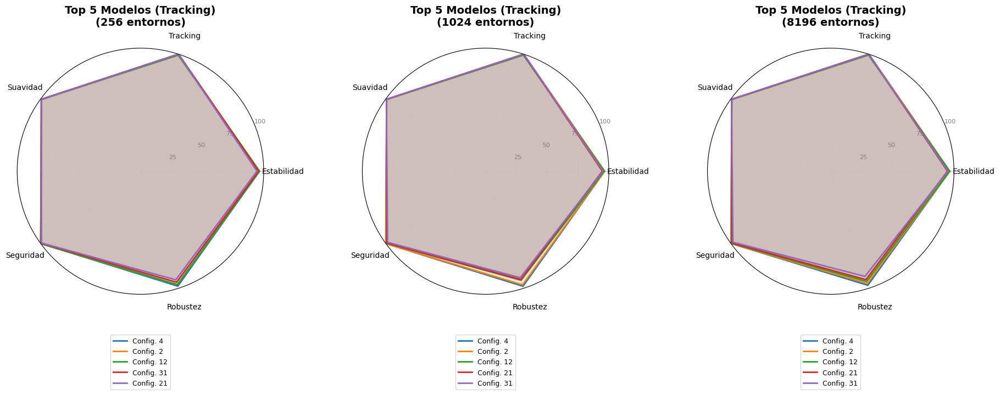

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# CONFIGURACIÓN PARA TRACKING
metrics = [
    "stability_pct",
    "tracking_pct",
    "smoothness_pct",
    "success_pct",
    "robustness_pct"
]

labels = [
    "Estabilidad",
    "Tracking",
    "Suavidad",
    "Seguridad",
    "Robustez"
]

TEST_ENVS = [256, 1024, 8196]


def rank_models(df, test_env):
    """
    Filtra un entorno de test concreto y rankea modelos
    """
    df_same_test = df[df["num_envs_test"] == test_env].copy()

    if df_same_test.empty: return df_same_test

    df_same_test["global_score"] = (
        0.35 * df_same_test["tracking_pct"] +
        0.25 * df_same_test["success_pct"] +
        0.20 * df_same_test["stability_pct"] +
        0.10 * df_same_test["robustness_pct"] +
        0.10 * df_same_test["smoothness_pct"]
    )

    df_ranked = (
        df_same_test
        .sort_values(by="global_score", ascending=False)
        .reset_index(drop=True)
    )

    return df_ranked


def compare_radar(ax, df, rows, title, label_col=None):
    """
    Dibuja radar chart optimizado para legibilidad con fondo blanco
    """
    angles = np.linspace(0, 2*np.pi, len(metrics), endpoint=False)
    angles = np.concatenate([angles, [angles[0]]])

    for row_idx in rows:
        values = df.loc[row_idx, metrics].values.astype(float)
        values = np.concatenate([values, [values[0]]])
        
        if label_col is None:
            raw_name = str(df.loc[row_idx, "id_run_name"])
            config_num = raw_name.split('_')[-1]
            label = f"Config. {config_num}"
        else:
            label = str(df.loc[row_idx, label_col])

        ax.plot(angles, values, linewidth=2, label=label)
        ax.fill(angles, values, alpha=0.1)

    
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels)
    ax.tick_params(axis='x', pad=15) 
    ax.set_ylim(0, 100)
    ax.set_facecolor('white') 
    ax.grid(True, color='silver', linestyle='--', alpha=0.7)
    ax.set_yticks([25, 50, 75, 100])
    ax.set_yticklabels(["25", "50", "75", "100"], color="grey", size=8)
    ax.set_title(title, pad=30, fontsize=14, fontweight='bold')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), 
              ncol=1, frameon=True, fontsize=9)

# Crear figura con 3 radares (Reorganizado)

plt.style.use('default')

fig, axes = plt.subplots(
    1, 3, 
    figsize=(22, 8), 
    subplot_kw=dict(polar=True)
)

fig.patch.set_facecolor('white')

found_data = False
for i, test_env in enumerate(TEST_ENVS):
    df_ranked = rank_models(df_plot, test_env)
    
    if df_ranked.empty:
        axes[i].text(0.5, 0.5, f"No data for\nEnv {test_env}", transform=axes[i].transAxes, ha='center')
        continue
        
    found_data = True
    top5_idx = df_ranked.index[:5].tolist()

    compare_radar(
        axes[i],
        df_ranked,
        top5_idx,
        f"Top 5 Modelos (Tracking)\n({test_env} entornos)" 
    )


plt.subplots_adjust(bottom=0.2, top=0.85, wspace=0.4)

if found_data:
    plt.show()
else:
    print("No se encontraron datos para los entornos especificados en TEST_ENVS")

🏆 TOP 5 MODELOS TRACKING: ANÁLISIS DE SOBREAJUSTE (TRAIN vs TEST) 🏆
  * Valores Δ negativos indican pérdida de rendimiento en Test respecto a Train
  * diff (%) muestra la caída porcentual de recompensa total entre Train y Test


,Modelo,Rew_Train,Rew_Test,Δ_Rew,diff (%),Score_Train,Score_Test,Track_Train,Track_Test,Δ_Track,...,Δ_Succ,Stab_Train,Stab_Test,Δ_Stab,Smooth_Train,Smooth_Test,Δ_Smooth,Rob_Train,Rob_Test,Δ_Rob
0,ppo_random_command15_4,381.93,382.01,0.08,0.02,98.64,99.02,100.00,100.00,0.00,...,0.01,96.24,96.52,0.28,97.32,99.23,1.91,96.71,97.96,1.25
1,ppo_random_command15_2,367.59,369.29,1.71,0.46,97.63,98.89,99.95,100.00,0.05,...,0.21,96.00,96.55,0.55,91.00,99.23,8.23,94.10,96.71,2.61
2,ppo_random_command15_12,357.45,359.03,1.58,0.44,96.30,98.34,99.25,99.23,-0.02,...,0.71,94.99,96.48,1.48,87.00,99.22,12.22,91.20,94.79,3.60
3,ppo_random_command15_21,366.31,366.16,-0.15,-0.04,97.68,97.94,100.00,100.00,0.00,...,0.45,94.56,94.67,0.11,98.60,99.40,0.81,92.21,92.63,0.42
4,ppo_random_command15_31,367.17,367.96,0.79,0.21,97.30,97.89,100.00,100.00,0.00,...,0.91,95.29,95.46,0.18,97.52,99.50,1.99,90.57,91.91,1.34


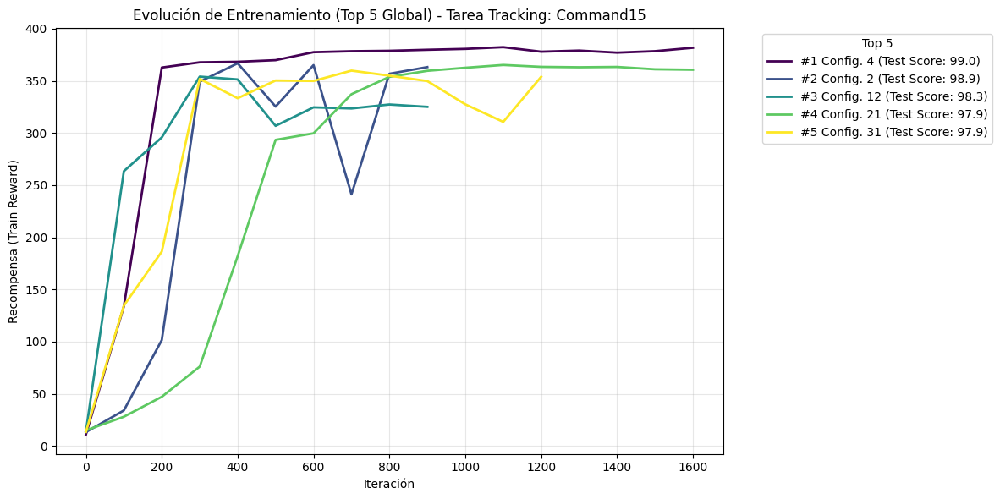

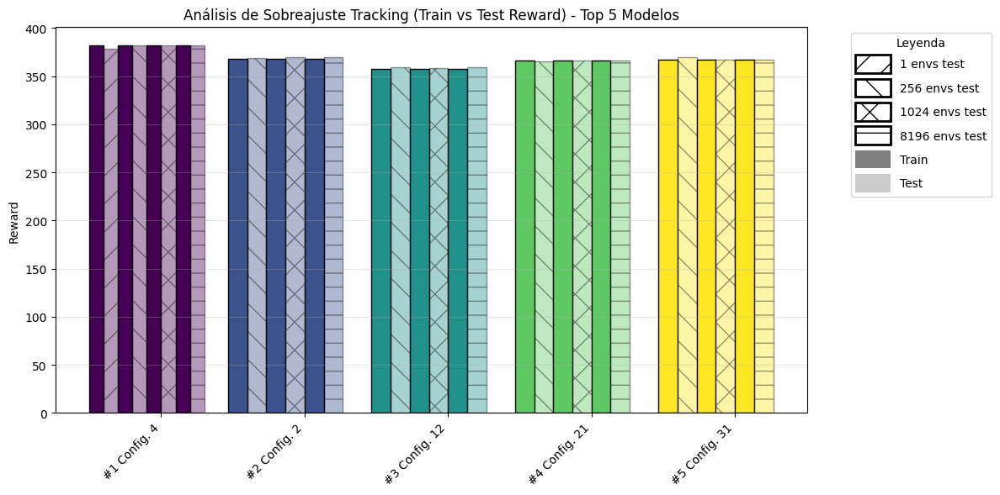

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display


# 1. Preparar Métricas de TEST (Promedio)
df_plot["global_score"] = (
    0.35 * df_plot["tracking_pct"] +
    0.25 * df_plot["success_pct"] +
    0.20 * df_plot["stability_pct"] +
    0.10 * df_plot["robustness_pct"] +
    0.10 * df_plot["smoothness_pct"]
)


col_test = ["reward_test", "tracking_pct", "success_pct", "stability_pct", "smoothness_pct", "robustness_pct", "global_score"]
df_test_mean = df_plot.groupby('id_run_name')[col_test].mean().reset_index()


# 2. Preparar Métricas de TRAIN

df_train = pd.read_csv(path_resultados + "/reward_best_models.csv")

def normalize_pct(x, xmin, xmax, invert=False):
    x_norm = (x - xmin) / (xmax - xmin)
    x_norm = np.clip(x_norm, 0, 1)
    if invert:
        x_norm = 1 - x_norm
    return x_norm * 100

MAX_POS = 1.5  
MAX_VEL = 7.0   
MAX_HEAD = 2.5 

MAX_TRACKING_TOTAL = MAX_POS + MAX_VEL + MAX_HEAD # = 11.0

def deshacer_exponencial(recompensa_obtenida, peso_maximo):
    """Solo se aplica a recompensas gaussianas (exp) para linealizar el error"""
    ratio = (recompensa_obtenida.clip(lower=0, upper=peso_maximo) / peso_maximo)
    return np.sqrt(ratio) * peso_maximo


df_train['stability_score'] = (
    df_train['mean_Episode_Reward/rew_attitude_stability2'] +
    df_train['mean_Episode_Reward/rew_ang_vel_stability4']
)

df_train['tracking_score'] = (
    deshacer_exponencial(df_train['mean_Episode_Reward/rew_pos2'], MAX_POS) +
    df_train['mean_Episode_Reward/rew_track_vel3'].clip(upper=MAX_VEL) +
    df_train['mean_Episode_Reward/rew_heading'].clip(upper=MAX_HEAD)
)

df_train['smoothness_score'] = -df_train['mean_Episode_Reward/rew_action_rate']
df_train['failure_rate'] = (
    df_train['mean_Episode_Termination/below_min_altitude'] +
    df_train['mean_Episode_Termination/bad_attitude'] +
    df_train['mean_Episode_Termination/safety_shutdown']
)
df_train['success_rate'] = 1 - df_train['failure_rate']

df_train['cv_train'] = df_train['std_reward'] / df_train['reward']


df_train["stability_pct"] = normalize_pct(df_train["stability_score"], 0.0, 3.0)
df_train["tracking_pct"] = normalize_pct(df_train["tracking_score"], 0.0, MAX_TRACKING_TOTAL) 
df_train["smoothness_pct"] = normalize_pct(df_train["smoothness_score"], 0.0, 0.016, invert=True)
df_train["success_pct"] = normalize_pct(df_train["success_rate"], 0.0, 1.0)
df_train["robustness_pct"] = normalize_pct(df_train["cv_train"], 0.0, 1.0, invert=True) 


df_train["global_score"] = (
    0.35 * df_train["tracking_pct"] +
    0.25 * df_train["success_pct"] +
    0.20 * df_train["stability_pct"] +
    0.10 * df_train["robustness_pct"] +
    0.10 * df_train["smoothness_pct"]
)


# 3. Cruzar TRAIN y TEST y calcular Diferencias (Top 5)

top5_model_names = df_test_mean.sort_values(by="global_score", ascending=False).head(5)['id_run_name'].tolist()

df_train_top5 = df_train[df_train['id_run_name'].isin(top5_model_names)].copy()
df_test_top5 = df_test_mean[df_test_mean['id_run_name'].isin(top5_model_names)].copy()


df_train_top5 = df_train_top5[['id_run_name', 'reward', 'global_score', 'tracking_pct', 'success_pct', 'stability_pct', 'smoothness_pct', 'robustness_pct']]
df_train_top5.columns = ['Modelo', 'Rew_Train', 'Score_Train', 'Track_Train', 'Succ_Train', 'Stab_Train', 'Smooth_Train', 'Rob_Train']

df_test_top5.columns = ['Modelo', 'Rew_Test', 'Track_Test', 'Succ_Test', 'Stab_Test', 'Smooth_Test', 'Rob_Test', 'Score_Test']

df_comp = pd.merge(df_train_top5, df_test_top5, on='Modelo')

# Calculamos Diferencias (Δ = Test - Train)
df_comp['Δ_Rew'] = df_comp['Rew_Test'] - df_comp['Rew_Train']
df_comp['diff (%)'] = (df_comp['Δ_Rew'] / df_comp['Rew_Train'].abs()) * 100
df_comp['Δ_Track'] = df_comp['Track_Test'] - df_comp['Track_Train']
df_comp['Δ_Succ'] = df_comp['Succ_Test'] - df_comp['Succ_Train']
df_comp['Δ_Stab'] = df_comp['Stab_Test'] - df_comp['Stab_Train']
df_comp['Δ_Smooth'] = df_comp['Smooth_Test'] - df_comp['Smooth_Train']
df_comp['Δ_Rob'] = df_comp['Rob_Test'] - df_comp['Rob_Train'] 


columnas_ordenadas = [
    'Modelo', 
    'Rew_Train', 'Rew_Test', 'Δ_Rew', 'diff (%)',
    'Score_Train', 'Score_Test',
    'Track_Train', 'Track_Test', 'Δ_Track',
    'Succ_Train', 'Succ_Test', 'Δ_Succ',
    'Stab_Train', 'Stab_Test', 'Δ_Stab',
    'Smooth_Train', 'Smooth_Test', 'Δ_Smooth',
    'Rob_Train', 'Rob_Test', 'Δ_Rob' 
]
df_comp = df_comp[columnas_ordenadas].sort_values(by='Score_Test', ascending=False).reset_index(drop=True).round(2)


# 4. Mostrar la Tabla Comparativa

print("="*145)
print("🏆 TOP 5 MODELOS TRACKING: ANÁLISIS DE SOBREAJUSTE (TRAIN vs TEST) 🏆")
print("  * Valores Δ negativos indican pérdida de rendimiento en Test respecto a Train")
print("  * diff (%) muestra la caída porcentual de recompensa total entre Train y Test")
print("="*145)
display(df_comp)

colors = plt.cm.viridis(np.linspace(0, 1, len(top5_model_names)))


# 5. Gráfica 1: Evolución de Entrenamiento (Train)

def get_group(value):
    if f"_{experiment_name}" in value:
        return task_name

df_copy = pd.read_csv(path_resultados + "/resultados_grid_PPO.csv")
df_copy["tarea"] = df_copy["id_run_name"].apply(get_group)

df_copy_reset = df_copy.reset_index()
if 'tarea' not in df_copy_reset.columns:
    df_copy_reset['tarea'] = df_copy_reset['id_run_name'].apply(get_group)
    
merged_df = df_copy_reset[df_copy_reset['id_run_name'].isin(top5_model_names)].copy()

for tarea, task_df in merged_df.groupby('tarea'):
    plt.figure(figsize=(12, 6))
    
    for i, run_name in enumerate(top5_model_names):
        subdf = task_df[task_df['id_run_name'] == run_name]
        if not subdf.empty:
            score = df_comp.loc[df_comp['Modelo'] == run_name, 'Score_Test'].values[0]
            
            config_num = str(run_name).split('_')[-1]
            label_name = f"#{i+1} Config. {config_num} (Test Score: {score:.1f})"
            
            plt.plot(subdf['iteration'], subdf['reward'], 
                     label=label_name, 
                     color=colors[i], linewidth=2)
            
    plt.xlabel('Iteración')
    plt.ylabel('Recompensa (Train Reward)')
    plt.title(f'Evolución de Entrenamiento (Top 5 Global) - Tarea Tracking: {tarea}')
    plt.legend(title="Top 5", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# 6. Gráfica 2: Sobreajuste (Train vs Test) Barras pareadas

df_bar = df_final[df_final["id_run_name"].isin(top5_model_names)].copy()

groups = top5_model_names
envs_test_vals = sorted(df_bar["num_envs_test"].unique())
x = np.arange(len(groups))

fig, ax = plt.subplots(figsize=(12, 6))

hatches = ['/', '\\', 'x', '-', '+', 'o', 'O', '.', '*']
hatch_map = {env: hatches[i % len(hatches)] for i, env in enumerate(envs_test_vals)}

for i, group in enumerate(groups):
    subset = df_bar[df_bar["id_run_name"] == group].sort_values("num_envs_test")
    n = len(subset)
    
    for j, (_, row) in enumerate(subset.iterrows()):
        offset = (j - n/2) * (0.8 / n)
        width = (0.8 / n) / 2
        base_color = colors[i]
        
        ax.bar(i + offset - width/2, row["reward_train"], width=width, color=base_color, alpha=1.0, edgecolor='black')
        ax.bar(i + offset + width/2, row["reward_test"], width=width, color=base_color, alpha=0.4, hatch=hatch_map[row["num_envs_test"]], edgecolor='black')

ax.set_xticks(x)


cleaned_labels = [f"#{idx+1} Config. {str(name).split('_')[-1]}" for idx, name in enumerate(groups)]
ax.set_xticklabels(cleaned_labels, rotation=45, ha='right')

ax.set_ylabel("Reward")
ax.set_title("Análisis de Sobreajuste Tracking (Train vs Test Reward) - Top 5 Modelos")

legend_hatch = [Patch(facecolor='white', edgecolor='black', hatch=hatch_map[env], linewidth=2, label=f"{env} envs test") for env in envs_test_vals]
legend_tt = [Patch(facecolor='gray', alpha=1.0, label="Train"), Patch(facecolor='gray', alpha=0.4, label="Test")]

ax.legend(handles=legend_hatch + legend_tt, title="Leyenda", bbox_to_anchor=(1.05, 1), loc='upper left', handleheight=2, handlelength=3)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Trayectorias

In [28]:
import os
import pandas as pd

df_callbacks = pd.read_csv(path_resultados+"/reward_best_models.csv", index_col='id_run_name')
powershell_script_test_7 = os.path.join(cfg_dir, "run_tests_7.ps1")

# --- CONFIGURACIÓN DE TRAYECTORIAS 3D ---
RECORD_STATES = True 
DIR_TRAYECTORIAS = path_resultados + "/trayectorias_3d" 


MODELO_OBJETIVO = str(df_comp.loc[0, "Modelo"]).split("_")[-1]
# ----------------------------------------


run_ids_encontrados = df_callbacks.index[df_callbacks.index.str.endswith(f"_{MODELO_OBJETIVO}")]

if len(run_ids_encontrados) == 0:
    print(f"[ERROR] No se ha encontrado ningún modelo que termine en _{MODELO_OBJETIVO} en el CSV.")
else:
  
    run_id = run_ids_encontrados[0]
    row = df_callbacks.loc[run_id]
    
    checkpoint_path = f"{path_resultados}/best_model_{run_id}_{int(row['num_envs_train'])}.pt"
    
    with open(powershell_script_test_7, "w") as f:
        f.write("$ErrorActionPreference = 'Stop'\n\n")
        f.write(f'Write-Host "Ejecutando Test final para Experimento {MODELO_OBJETIVO}..."\n')
        

        cmd = (f'& "{isaaclab_bat}" -p "{play_script}" '
               f'--task {id_task}-{MODELO_OBJETIVO} '
               f'--num_envs 256 '
               f'--headless '
               f'--seed {test_seed} '
               f'--checkpoint "{checkpoint_path}" '
               f'--record_states --states_csv_dir "{DIR_TRAYECTORIAS}"')
            
        cmd += '\n\n'
        f.write(cmd)
        
    print(f"✅ Script de test generado exclusivamente para el modelo {MODELO_OBJETIVO} en: {powershell_script_test_7}")

✅ Script de test generado exclusivamente para el modelo 4 en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_7.ps1


In [29]:
# !powershell -ExecutionPolicy Bypass -File "{powershell_script}"
import subprocess
import sys


powershell_script_path = powershell_script_test_7 

print(f"Iniciando ejecución de: {powershell_script_path}\n")
process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, 
    text=True,
    bufsize=1
)

try:
    for line in process.stdout:
        print(line, end="")  
        sys.stdout.flush()   
except KeyboardInterrupt:
    process.kill()
    print("\nEntrenamiento cancelado por el usuario.")

process.wait()
print("\n--- Todos los experimentos de test han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_7.ps1

Ejecutando Test final para Experimento 4...
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261106_172659.log
2026-11-06T16:26:59Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-06T16:27:00Z s] [Warning] [carb] Acquiring non optional plugin interface which is not listed as depend

📊 Evaluando Modelo: ppo_random_command15_4
✅ Graficando Dron ID: 67.0 (Error medio: 1.20 m)


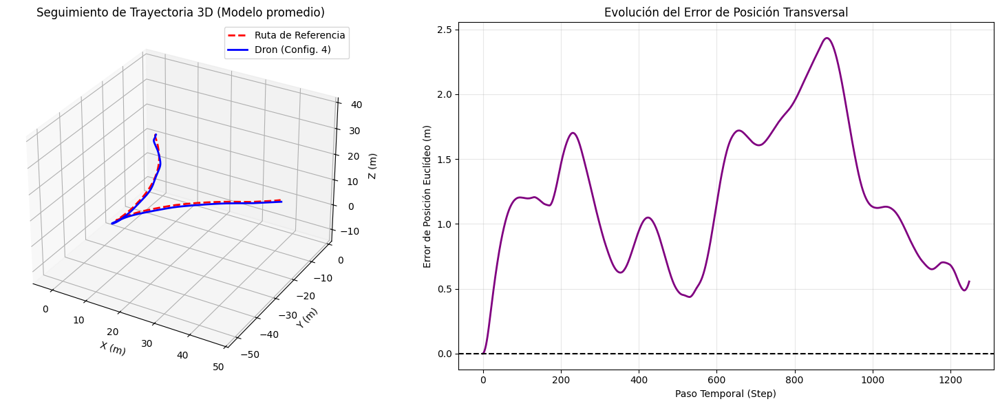

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 1. CONFIGURACIÓN
MODELO_OBJETIVO = str(df_comp.loc[0, "Modelo"]).split("_")[-1]
run_name = f"ppo_random_{experiment_name}_{MODELO_OBJETIVO}" 


csv_path = f"{path_resultados}/trayectorias_3d/tracking_3D_{run_name}.csv"


# 2. PROCESAMIENTO DE DATOS
df_states = pd.read_csv(csv_path)


df_states['pos_error'] = np.sqrt(
    (df_states['drone_x'] - df_states['target_x'])**2 + 
    (df_states['drone_y'] - df_states['target_y'])**2 + 
    (df_states['drone_z'] - df_states['target_z'])**2
)


error_por_dron = df_states.groupby('env_id')['pos_error'].mean().reset_index()
error_por_dron = error_por_dron.sort_values(by='pos_error').reset_index(drop=True)

id_mejor = error_por_dron.iloc[0]['env_id']
id_mediana = error_por_dron.iloc[len(error_por_dron) // 2]['env_id']

# --- SELECCIÓN DEL DRON A GRAFICAR ---
# Por defecto grafica el mediano para representar la fiabilidad estadística general de la política.
# Si quieres ver el comportamiento ideal, cambia 'id_mediana' por 'id_mejor'.
id_elegido = id_mediana 

print(f"📊 Evaluando Modelo: {run_name}")
print(f"✅ Graficando Dron ID: {id_elegido} (Error medio: {error_por_dron[error_por_dron['env_id'] == id_elegido]['pos_error'].values[0]:.2f} m)")


df_dron = df_states[df_states['env_id'] == id_elegido].sort_values(by='step')


# 3. GENERACIÓN DE LA GRÁFICA

plt.style.use('default')
fig = plt.figure(figsize=(16, 6))

# --- GRÁFICA 1: TRAYECTORIA 3D ---
ax1 = fig.add_subplot(121, projection='3d')

# Dibujamos la ruta de referencia (Objetivo)
ax1.plot(df_dron['target_x'], df_dron['target_y'], df_dron['target_z'], 
         label='Ruta de Referencia', color='red', linestyle='--', linewidth=2)

# Dibujamos la trayectoria seguida por el dron
ax1.plot(df_dron['drone_x'], df_dron['drone_y'], df_dron['drone_z'], 
         label=f'Dron (Config. {run_name.split("_")[-1]})', color='blue', linewidth=2)

ax1.set_xlabel('X (m)')
ax1.set_ylabel('Y (m)')
ax1.set_zlabel('Z (m)')
ax1.set_title(f'Seguimiento de Trayectoria 3D (Modelo promedio)')
ax1.legend()


limites = np.array([ax1.get_xlim3d(), ax1.get_ylim3d(), ax1.get_zlim3d()])
centro = np.mean(limites, axis=1)
max_radio = max(limites[:, 1] - limites[:, 0]) / 2
ax1.set_xlim3d([centro[0] - max_radio, centro[0] + max_radio])
ax1.set_ylim3d([centro[1] - max_radio, centro[1] + max_radio])
ax1.set_zlim3d([centro[2] - max_radio, centro[2] + max_radio])

# --- GRÁFICA 2: ERROR DE POSICIÓN ---
ax2 = fig.add_subplot(122)
ax2.plot(df_dron['step'], df_dron['pos_error'], color='purple', linewidth=2)


ax2.axhline(y=0, color='black', linestyle='--')

ax2.set_xlabel('Paso Temporal (Step)')
ax2.set_ylabel('Error de Posición Euclídeo (m)')
ax2.set_title('Evolución del Error de Posición Transversal')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

📊 Evaluando Modelo: ppo_random_command15_4
✅ Graficando Dron ID: 67.0 (Error medio: 1.20 m)
🚀 Velocidad del dron (fuente: simulador (drone_vel_*)): media 3.98 m/s · máx 5.68 m/s (horizontal: media 3.95 m/s)
🎯 Velocidad de la referencia: media 3.84 m/s · máx 4.80 m/s | error de velocidad medio 0.47 m/s
👥 Todos los drones (256): velocidad media por dron = 4.06 m/s (percentil 5-95: 2.96–5.25 m/s)


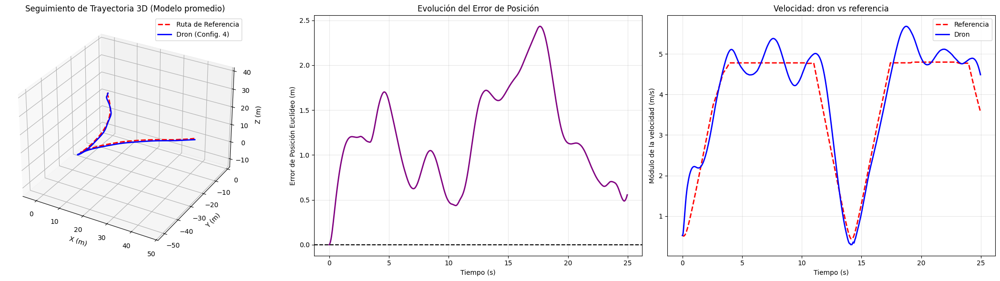

In [18]:
# ==============================================================================
# TRAYECTORIA 3D + ERROR DE POSICIÓN + VELOCIDAD (dron vs referencia) del modelo objetivo
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DT = 0.02   # env.step_dt: un paso de control = 0.02 s (1250 pasos = 25 s)

# 1. CONFIGURACIÓN
run_name = f"ppo_random_{experiment_name}_{MODELO_OBJETIVO}"
csv_path = f"{path_resultados}/trayectorias_3d/tracking_3D_{run_name}.csv"

# 2. PROCESAMIENTO DE DATOS
df_states = pd.read_csv(csv_path)

df_states['pos_error'] = np.sqrt(
    (df_states['drone_x'] - df_states['target_x'])**2 +
    (df_states['drone_y'] - df_states['target_y'])**2 +
    (df_states['drone_z'] - df_states['target_z'])**2
)

error_por_dron = df_states.groupby('env_id')['pos_error'].mean().reset_index()
error_por_dron = error_por_dron.sort_values(by='pos_error').reset_index(drop=True)

id_mejor = error_por_dron.iloc[0]['env_id']
id_mediana = error_por_dron.iloc[len(error_por_dron) // 2]['env_id']

# --- SELECCIÓN DEL DRON A GRAFICAR ---
# Por defecto grafica el mediano (representa el comportamiento típico, no el mejor caso).
# Si quieres ver el comportamiento ideal, cambia 'id_mediana' por 'id_mejor'.
id_elegido = id_mediana


def add_speeds(df, dt=DT):
    """Añade tiempo (s) y velocidades (m/s) del dron y de la referencia.
    Usa drone_vel_* / target_vel_* si el CSV las trae (play.py parcheado); si no, deriva la posición."""
    d = df.sort_values("step").copy()
    d["t"] = d["step"] * dt
    if {"drone_vel_x", "drone_vel_y", "drone_vel_z"} <= set(d.columns):
        v = d[["drone_vel_x", "drone_vel_y", "drone_vel_z"]].to_numpy()
        origen = "simulador (drone_vel_*)"
    else:
        v = np.gradient(d[["drone_x", "drone_y", "drone_z"]].to_numpy(), dt, axis=0)
        origen = "diferencias finitas de la posición"
    if {"target_vel_x", "target_vel_y", "target_vel_z"} <= set(d.columns):
        vt = d[["target_vel_x", "target_vel_y", "target_vel_z"]].to_numpy()
    else:
        vt = np.gradient(d[["target_x", "target_y", "target_z"]].to_numpy(), dt, axis=0)
    d["speed"],   d["speed_xy"]   = np.linalg.norm(v, axis=1),  np.linalg.norm(v[:, :2], axis=1)
    d["speed_t"], d["speed_t_xy"] = np.linalg.norm(vt, axis=1), np.linalg.norm(vt[:, :2], axis=1)
    d["vel_err"] = np.linalg.norm(v - vt, axis=1)
    return d, origen


df_dron = df_states[df_states['env_id'] == id_elegido]
df_dron, origen_vel = add_speeds(df_dron)

print(f"📊 Evaluando Modelo: {run_name}")
print(f"✅ Graficando Dron ID: {id_elegido} (Error medio: {error_por_dron[error_por_dron['env_id'] == id_elegido]['pos_error'].values[0]:.2f} m)")
print(f"🚀 Velocidad del dron (fuente: {origen_vel}): media {df_dron.speed.mean():.2f} m/s · máx {df_dron.speed.max():.2f} m/s "
      f"(horizontal: media {df_dron.speed_xy.mean():.2f} m/s)")
print(f"🎯 Velocidad de la referencia: media {df_dron.speed_t.mean():.2f} m/s · máx {df_dron.speed_t.max():.2f} m/s "
      f"| error de velocidad medio {df_dron.vel_err.mean():.2f} m/s")

# Estadística de TODA la población (solo si el CSV trae la velocidad del simulador)
if {"drone_vel_x", "drone_vel_y", "drone_vel_z"} <= set(df_states.columns):
    sp = np.linalg.norm(df_states[["drone_vel_x", "drone_vel_y", "drone_vel_z"]].to_numpy(), axis=1)
    media_env = pd.Series(sp, index=df_states.index).groupby(df_states['env_id']).mean()
    print(f"👥 Todos los drones ({df_states['env_id'].nunique()}): velocidad media por dron = {media_env.mean():.2f} m/s "
          f"(percentil 5-95: {media_env.quantile(0.05):.2f}–{media_env.quantile(0.95):.2f} m/s)")

# 3. GENERACIÓN DE LA GRÁFICA
plt.style.use('default')
fig = plt.figure(figsize=(22, 6))

# --- GRÁFICA 1: TRAYECTORIA 3D ---
ax1 = fig.add_subplot(131, projection='3d')

ax1.plot(df_dron['target_x'], df_dron['target_y'], df_dron['target_z'],
         label='Ruta de Referencia', color='red', linestyle='--', linewidth=2)
ax1.plot(df_dron['drone_x'], df_dron['drone_y'], df_dron['drone_z'],
         label=f'Dron (Config. {run_name.split("_")[-1]})', color='blue', linewidth=2)

ax1.set_xlabel('X (m)')
ax1.set_ylabel('Y (m)')
ax1.set_zlabel('Z (m)')
ax1.set_title('Seguimiento de Trayectoria 3D (Modelo promedio)')
ax1.legend()

limites = np.array([ax1.get_xlim3d(), ax1.get_ylim3d(), ax1.get_zlim3d()])
centro = np.mean(limites, axis=1)
max_radio = max(limites[:, 1] - limites[:, 0]) / 2
ax1.set_xlim3d([centro[0] - max_radio, centro[0] + max_radio])
ax1.set_ylim3d([centro[1] - max_radio, centro[1] + max_radio])
ax1.set_zlim3d([centro[2] - max_radio, centro[2] + max_radio])

# --- GRÁFICA 2: ERROR DE POSICIÓN ---
ax2 = fig.add_subplot(132)
ax2.plot(df_dron['t'], df_dron['pos_error'], color='purple', linewidth=2)
ax2.axhline(y=0, color='black', linestyle='--')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Error de Posición Euclídeo (m)')
ax2.set_title('Evolución del Error de Posición')
ax2.grid(True, alpha=0.3)

# --- GRÁFICA 3: VELOCIDAD ---
ax3 = fig.add_subplot(133)
ax3.plot(df_dron['t'], df_dron['speed_t'], color='red', linestyle='--', linewidth=2, label='Referencia')
ax3.plot(df_dron['t'], df_dron['speed'], color='blue', linewidth=2, label='Dron')
ax3.set_xlabel('Tiempo (s)')
ax3.set_ylabel('Módulo de la velocidad (m/s)')
ax3.set_title('Velocidad: dron vs referencia')
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()

#### Evaluación multisemilla, con viento y retraso en los actuadores

In [30]:
os.makedirs(path_resultados_ev2, exist_ok=True)

powershell_script_test_8 = os.path.join(cfg_dir, "run_tests_8.ps1")
num_envs_eval = 1024

cfg_best_model = os.path.join(cfg_dir, f"ppo_random_{experiment_name}_{MODELO_OBJETIVO}_cfg.py")
cfg_best_model_clon = os.path.join(cfg_dir, f"ppo_random_{experiment_name}_90_cfg.py")


with open(cfg_best_model) as f:
    lineas = f.readlines()

with open(cfg_best_model_clon, "w") as f:
    for linea in lineas:
        if linea.strip().startswith("csv_path_metrics"):
            linea = f'    csv_path_metrics = "{path_resultados_ev2}"\n'
        f.write(linea)

eval_seeds = [1001, 1002, 1003, 1004, 1005]

eval_delays = [
    {"tau_ms": 0.0,   "tag": "tau_0ms",   "label": "0 ms"},
    {"tau_ms": 20.0,  "tag": "tau_20ms",  "label": "20 ms"},
    {"tau_ms": 40.0,  "tag": "tau_40ms",  "label": "40 ms"},
    {"tau_ms": 80.0,  "tag": "tau_80ms",  "label": "ood, 80 ms"},
    {"tau_ms": 120.0, "tag": "tau_120ms", "label": "ood, 120 ms"}
]

eval_winds = [
    {"wind_ms": 0.0,  "gust_std": 0.0, "tag": "wind_0ms",  "label": "0 m/s, g=0"},
    {"wind_ms": 4.0,  "gust_std": 1.5, "tag": "wind_4ms",  "label": "4 m/s, g=1.5"},
    {"wind_ms": 8.0,  "gust_std": 2.0, "tag": "wind_8ms",  "label": "8 m/s, g=2"},
    {"wind_ms": 12.0, "gust_std": 3.5, "tag": "wind_12ms", "label": "ood, 12 m/s, g=3.5"},
    {"wind_ms": 16.0, "gust_std": 5.0, "tag": "wind_16ms", "label": "ood,16 m/s, g=5"}
]


eval_experiments = []


for s in eval_seeds:
    eval_experiments.append({
        "eval_group": "Multisemilla",
        "condition": f"Seed {s}",
        "tag": f"seed_{s}",
        "seed": s,
        "tau_ms": None,
        "wind_ms": None,
        "gust_std": None
    })


for d in eval_delays:
    eval_experiments.append({
        "eval_group": "Retardo",
        "condition": d["label"],
        "tag": d["tag"],
        "seed": test_seed,
        "tau_ms": d["tau_ms"],
        "wind_ms": None,
        "gust_std": None
    })


for w in eval_winds:
    eval_experiments.append({
        "eval_group": "Viento",
        "condition": w["label"],
        "tag": w["tag"],
        "seed": test_seed,
        "tau_ms": None,
        "wind_ms": w["wind_ms"],
        "gust_std": w["gust_std"]
    })

df_experiments = pd.DataFrame(eval_experiments)
df_experiments["orden"] = range(len(df_experiments))

# --- GENERADOR DEL SCRIPT POWERSHELL ---
with open(powershell_script_test_8, "w") as f:
    f.write("$ErrorActionPreference = 'Stop'\n\n")

    for item in eval_experiments:
        f.write(f'Write-Host "Evaluando {item["tag"]} (Experimento {MODELO_OBJETIVO})..."\n')

        if item["tau_ms"] is not None:
            f.write(f'$env:AEROTAXI_TAU_MS = "{item["tau_ms"]}"\n')
        else:
            f.write('Remove-Item Env:\\AEROTAXI_TAU_MS -ErrorAction SilentlyContinue\n')

        if item["wind_ms"] is not None:
            f.write(f'$env:AEROTAXI_WIND_MS = "{item["wind_ms"]}"\n')
        else:
            f.write('Remove-Item Env:\\AEROTAXI_WIND_MS -ErrorAction SilentlyContinue\n')

        if item["gust_std"] is not None:
            f.write(f'$env:AEROTAXI_GUST_STD = "{item["gust_std"]}"\n')
        else:
            f.write('Remove-Item Env:\\AEROTAXI_GUST_STD -ErrorAction SilentlyContinue\n')

        cmd = (f'& "{isaaclab_bat}" -p "{play_script}" '
               f'--task {id_task}-90 '
               f'--num_envs {num_envs_eval} '
               f'--headless '
               f'--seed {item["seed"]} '
               f'--checkpoint "{checkpoint_path}" '
               f'--tag "{item["tag"]}"')

        cmd += '\n\n'
        f.write(cmd)


    f.write('Remove-Item Env:\\AEROTAXI_TAU_MS -ErrorAction SilentlyContinue\n')
    f.write('Remove-Item Env:\\AEROTAXI_WIND_MS -ErrorAction SilentlyContinue\n')
    f.write('Remove-Item Env:\\AEROTAXI_GUST_STD -ErrorAction SilentlyContinue\n')

print(f"Modelo {run_id}, checkpoint: {checkpoint_path}")
print(f"Script de evaluación generado en: {powershell_script_test_8}: {len(eval_experiments)} evaluaciones)")

Modelo ppo_random_command15_4, checkpoint: C:/Users/Teresa/Documents/GitHub/navsim/tmp/tmpTeresa/resultados_grid_command_v19/best_model_ppo_random_command15_4_8196.pt
Script de evaluación generado en: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_8.ps1: 15 evaluaciones)


In [31]:
import sys
powershell_script_path = powershell_script_test_8

print(f"Iniciando ejecución de: {powershell_script_path}\n")
process = subprocess.Popen(
    ["powershell.exe", "-ExecutionPolicy", "Bypass", "-File", powershell_script_path],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

try:
    for line in process.stdout:
        print(line, end="")
        sys.stdout.flush()
except KeyboardInterrupt:
    process.kill()
    print("\nEvaluación cancelada por el usuario.")

process.wait()
print("\n--- Todos los experimentos de evaluación han finalizado ---")

Iniciando ejecución de: C:/Users/Teresa/Documents/GitHub/navsim/isaac_lab/aerotaxi/env_command/env_19/grid_hiperparametros/cfg_files\run_tests_8.ps1

Evaluando seed_1001 (Experimento 4)...
[INFO] Using python from: C:\Users\Teresa\miniconda3\envs\env_isaaclab\python.exe
[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: C:\Users\Teresa\miniconda3\envs\env_isaaclab\Lib\site-packages\isaaclab\apps\isaaclab.python.headless.kit
Loading user config located at: 'c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: c:/users/teresa/miniconda3/envs/env_isaaclab/lib/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261112_101154.log
2026-11-12T09:11:55Z s] [Warning] [omni.usd_config.extension] Enable omni.materialx.libs extension to use MaterialX
2026-11-12T09:11:56Z [1,549ms] [Warning] [carb] Acquiring non optional plugin interface which is not listed as depe

Métricas exportadas en: C:/Users/Teresa/Documents/GitHub/navsim/tmp/tmpTeresa/resultados_env19_ev2/metricas_robustez_ppo_random_command15_4.csv

Evaluación: Multisemilla | Modelo: ppo_random_command15_4 | 1024 entornos


,Condición,Global Score,Reward Test,Std Test,Tracking (%),Seguridad (%),Estabilidad (%),Robustez (%),Suavidad (%),Caídas Totales (%),Caída Altitud (%),Caída Actitud (%),Safety Shutdown (%)
0,Seed 1001,99.06,382.18,6.57,100.0,100.0,96.57,98.28,99.23,0.0,0.0,0.0,0.0
1,Seed 1002,98.93,382.04,10.20,100.0,99.9,96.49,97.33,99.23,0.1,0.0,0.1,0.0
2,Seed 1003,99.07,382.23,6.24,100.0,100.0,96.55,98.37,99.23,0.0,0.0,0.0,0.0
3,Seed 1004,99.06,382.34,6.68,100.0,100.0,96.58,98.25,99.23,0.0,0.0,0.0,0.0
4,Seed 1005,99.06,381.93,6.76,100.0,100.0,96.56,98.23,99.22,0.0,0.0,0.0,0.0



Evaluación: Retardo | Modelo: ppo_random_command15_4 | 1024 entornos


,Condición,Global Score,Reward Test,Std Test,Tracking (%),Seguridad (%),Estabilidad (%),Robustez (%),Suavidad (%),Caídas Totales (%),Caída Altitud (%),Caída Actitud (%),Safety Shutdown (%)
0,0 ms,99.08,382.38,6.42,100.0,100.00,96.62,98.32,99.20,0.00,0.00,0.00,0.0
1,20 ms,99.07,382.21,6.56,100.0,100.00,96.58,98.28,99.23,0.00,0.00,0.00,0.0
2,40 ms,98.90,381.63,10.62,100.0,99.90,96.41,97.22,99.24,0.10,0.10,0.00,0.0
3,"ood, 80 ms",98.21,378.88,26.35,100.0,99.41,95.63,93.04,99.27,0.59,0.39,0.20,0.0
4,"ood, 120 ms",95.39,364.75,66.53,100.0,95.61,91.89,81.76,99.31,4.39,1.66,2.73,0.0



Evaluación: Viento | Modelo: ppo_random_command15_4 | 1024 entornos


,Condición,Global Score,Reward Test,Std Test,Tracking (%),Seguridad (%),Estabilidad (%),Robustez (%),Suavidad (%),Caídas Totales (%),Caída Altitud (%),Caída Actitud (%),Safety Shutdown (%)
0,"0 m/s, g=0",99.06,382.27,6.58,100.0,100.0,96.57,98.28,99.22,0.0,0.0,0.0,0.0
1,"4 m/s, g=1.5",99.06,382.23,6.56,100.0,100.0,96.57,98.28,99.22,0.0,0.0,0.0,0.0
2,"8 m/s, g=2",99.06,382.00,6.53,100.0,100.0,96.56,98.29,99.23,0.0,0.0,0.0,0.0
3,"ood, 12 m/s, g=3.5",99.04,381.34,6.60,100.0,100.0,96.46,98.27,99.24,0.0,0.0,0.0,0.0
4,"ood,16 m/s, g=5",98.98,379.73,6.96,100.0,100.0,96.17,98.17,99.25,0.0,0.0,0.0,0.0


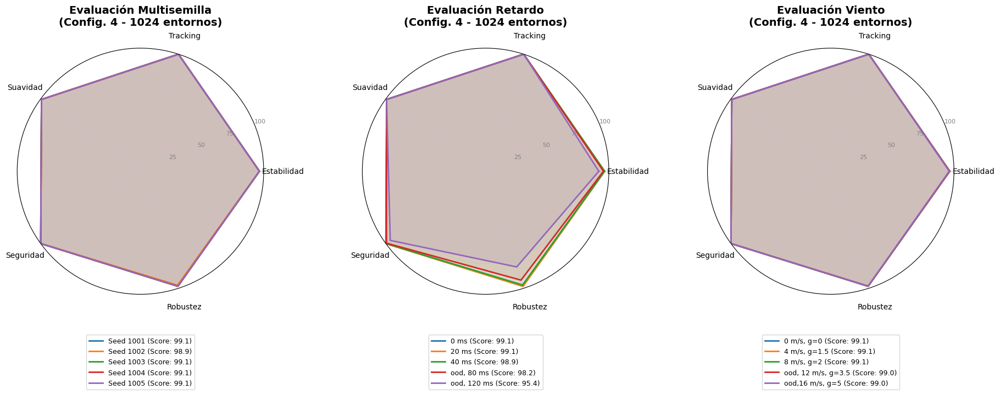

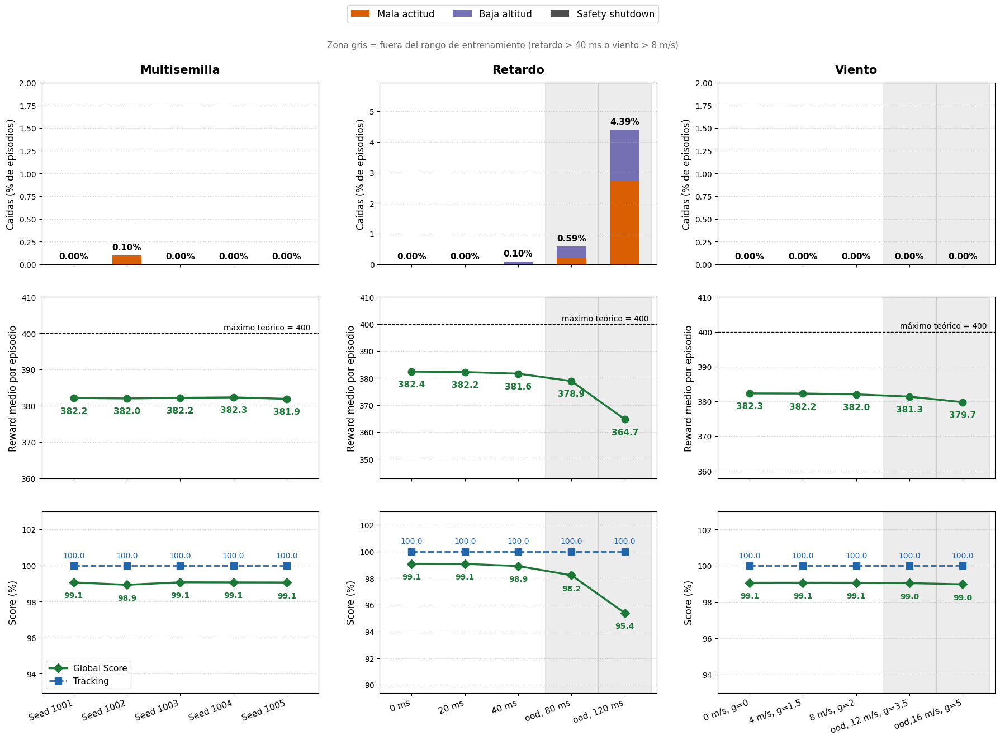

In [33]:
df_metrics_ev = pd.read_csv(path_resultados_ev2 + "/rewards_play_PPO.csv")
df_metrics_ev = df_metrics_ev[df_metrics_ev["num_envs_test"] == num_envs_eval]
df_metrics_ev = df_metrics_ev[df_metrics_ev["id_run_name"] == run_id]
df_metrics_ev = df_metrics_ev.drop_duplicates(subset=["tag"], keep="last")
df_metrics_ev = df_metrics_ev.reset_index(drop=True)

df_metrics_ev["stability_score"] = (
    df_metrics_ev["mean_Episode_Reward/rew_attitude_stability2"] +
    df_metrics_ev["mean_Episode_Reward/rew_ang_vel_stability4"]
)

df_metrics_ev["tracking_score"] = (
    deshacer_exponencial(df_metrics_ev["mean_Episode_Reward/rew_pos2"], MAX_POS) +
    df_metrics_ev["mean_Episode_Reward/rew_track_vel3"].clip(upper=MAX_VEL) +
    df_metrics_ev["mean_Episode_Reward/rew_heading"].clip(upper=MAX_HEAD)
)

df_metrics_ev["smoothness_score"] = -df_metrics_ev["mean_Episode_Reward/rew_action_rate"]

df_metrics_ev["failure_rate"] = (
    df_metrics_ev["mean_Episode_Termination/below_min_altitude"] +
    df_metrics_ev["mean_Episode_Termination/bad_attitude"] +
    df_metrics_ev["mean_Episode_Termination/safety_shutdown"]
)

df_metrics_ev["success_rate"] = 1 - df_metrics_ev["failure_rate"]
df_metrics_ev["cv_test"] = df_metrics_ev["std"] / df_metrics_ev["reward"]

df_plot_ev = df_experiments.merge(df_metrics_ev, on="tag", how="inner")


df_plot_ev["stability_scaled"] = normalize(
    df_plot_ev["stability_score"],
    xmin=0.0,
    xmax=3.0
)

df_plot_ev["tracking_scaled"] = normalize(
    df_plot_ev["tracking_score"],
    xmin=0.0,
    xmax=MAX_TRACKING_TOTAL
)

df_plot_ev["smoothness_scaled"] = normalize(
    df_plot_ev["smoothness_score"],
    xmin=0.0,
    xmax=0.016,
    invert=True
)

df_plot_ev["success_scaled"] = normalize(
    df_plot_ev["success_rate"],
    xmin=0.0,
    xmax=1.0
)

df_plot_ev["robustness_scaled"] = normalize(
    df_plot_ev["cv_test"],
    xmin=0.0,
    xmax=1.0,
    invert=True
)

for col in scaled_cols:
    df_plot_ev[col.replace("_scaled", "_pct")] = df_plot_ev[col] * 100


df_plot_ev = rank_models(df_plot_ev, num_envs_eval)
df_plot_ev = df_plot_ev.sort_values(by="orden").reset_index(drop=True)


df_plot_ev["failure_pct"] = df_plot_ev["failure_rate"] * 100
df_plot_ev["fall_alt_pct"] = df_plot_ev["mean_Episode_Termination/below_min_altitude"] * 100
df_plot_ev["fall_attitude_pct"] = df_plot_ev["mean_Episode_Termination/bad_attitude"] * 100
df_plot_ev["fall_shutdown_pct"] = df_plot_ev["mean_Episode_Termination/safety_shutdown"] * 100

df_plot_ev["radar_label"] = (
    df_plot_ev["condition"] + " (Score: " +
    df_plot_ev["global_score"].round(1).astype(str) + ")"
)

df_plot_ev.to_csv(path_resultados_ev2 + f"/metricas_robustez_{run_id}.csv", index=False)
print(f"Métricas exportadas en: {path_resultados_ev2}/metricas_robustez_{run_id}.csv")

# ==============================================================================
# TABLAS COMPARATIVAS
# ==============================================================================
cols_tabla = [
    "condition", "global_score", "reward", "std",
    "tracking_pct", "success_pct", "stability_pct", "robustness_pct", "smoothness_pct",
    "failure_pct", "fall_alt_pct", "fall_attitude_pct", "fall_shutdown_pct"
]

nombres_tabla = {
    "condition": "Condición",
    "global_score": "Global Score",
    "reward": "Reward Test",
    "std": "Std Test",
    "tracking_pct": "Tracking (%)",
    "success_pct": "Seguridad (%)",
    "stability_pct": "Estabilidad (%)",
    "robustness_pct": "Robustez (%)",
    "smoothness_pct": "Suavidad (%)",
    "failure_pct": "Caídas Totales (%)",
    "fall_alt_pct": "Caída Altitud (%)",
    "fall_attitude_pct": "Caída Actitud (%)",
    "fall_shutdown_pct": "Safety Shutdown (%)"
}

grupos_eval = ["Multisemilla", "Retardo", "Viento"]

for grupo in grupos_eval:
    df_sub = df_plot_ev[df_plot_ev["eval_group"] == grupo]
    df_sub = df_sub[cols_tabla]
    df_sub = df_sub.rename(columns=nombres_tabla)
    df_sub = df_sub.reset_index(drop=True)

    print(f"\nEvaluación: {grupo} | Modelo: {run_id} | {num_envs_eval} entornos")
    display(df_sub.round(2))


plt.style.use('default')
fig, axes = plt.subplots(1, 3, figsize=(22, 8), subplot_kw=dict(polar=True))
fig.patch.set_facecolor('white')

for i, grupo in enumerate(grupos_eval):
    df_g = df_plot_ev[df_plot_ev["eval_group"] == grupo]
    df_g = df_g.reset_index(drop=True)

    compare_radar(
        axes[i],
        df_g,
        df_g.index.tolist(),
        f"Evaluación {grupo}\n(Config. {MODELO_OBJETIVO} - {num_envs_eval} entornos)",
        label_col="radar_label"
    )

plt.subplots_adjust(bottom=0.2, top=0.85, wspace=0.4)
plt.savefig(path_resultados_ev2 + f"/radares_{run_id}_{num_envs_eval}envs.png", dpi=300, bbox_inches="tight")
plt.show()


fig, axes = plt.subplots(3, 3, figsize=(22, 14))
fig.patch.set_facecolor('white')

for i, grupo in enumerate(grupos_eval):
    df_g = df_plot_ev[df_plot_ev["eval_group"] == grupo]
    df_g = df_g.reset_index(drop=True)
    x = np.arange(len(df_g))

    ax_caidas = axes[0, i]
    ax_reward = axes[1, i]
    ax_score = axes[2, i]


    for j in range(len(df_g)):
        fuera = False
        if df_g.loc[j, "tau_ms"] > 40:
            fuera = True
        if df_g.loc[j, "wind_ms"] > 8:
            fuera = True
        if fuera:
            ax_caidas.axvspan(j - 0.5, j + 0.5, color="grey", alpha=0.15)
            ax_reward.axvspan(j - 0.5, j + 0.5, color="grey", alpha=0.15)
            ax_score.axvspan(j - 0.5, j + 0.5, color="grey", alpha=0.15)


    total_caidas = df_g["fall_attitude_pct"] + df_g["fall_alt_pct"] + df_g["fall_shutdown_pct"]
    ymax_caidas = max(total_caidas.max() * 1.35, 2.0)

    ax_caidas.bar(x, df_g["fall_attitude_pct"], width=0.55, color="#d95f02", label="Mala actitud")
    ax_caidas.bar(x, df_g["fall_alt_pct"], width=0.55, bottom=df_g["fall_attitude_pct"],
                  color="#7570b3", label="Baja altitud")
    ax_caidas.bar(x, df_g["fall_shutdown_pct"], width=0.55,
                  bottom=df_g["fall_attitude_pct"] + df_g["fall_alt_pct"],
                  color="#4d4d4d", label="Safety shutdown")
    ax_caidas.set_ylim(0, ymax_caidas)

    for j in range(len(df_g)):
        ax_caidas.text(x[j], total_caidas[j] + ymax_caidas * 0.02, f"{total_caidas[j]:.2f}%",
                       ha="center", va="bottom", fontsize=11, fontweight="bold")

    ax_caidas.set_title(f"{grupo}", fontsize=15, fontweight="bold", pad=12)
    ax_caidas.set_ylabel("Caídas (% de episodios)", fontsize=12)


    ax_reward.plot(x, df_g["reward"], color="#1b7837", marker="o", linewidth=2.5, markersize=9)
    ax_reward.axhline(y=400, color="black", linestyle="--", linewidth=1)
    ax_reward.text(len(df_g) - 0.55, 400.5, "máximo teórico = 400", ha="right", va="bottom", fontsize=10)
    ax_reward.set_ylim(df_g["reward"].min() - 22, 410)

    for j in range(len(df_g)):
        ax_reward.annotate(f"{df_g.loc[j, 'reward']:.1f}", (x[j], df_g.loc[j, "reward"]),
                           textcoords="offset points", xytext=(0, -20),
                           ha="center", fontsize=11, fontweight="bold", color="#1b7837")

    ax_reward.set_ylabel("Reward medio por episodio", fontsize=12)


    ax_score.plot(x, df_g["global_score"], color="#1b7837", marker="D", linewidth=2.5,
                  markersize=8, label="Global Score")
    ax_score.plot(x, df_g["tracking_pct"], color="#2166ac", marker="s", linestyle="--",
                  linewidth=2, markersize=8, label="Tracking")
    ymin_score = min(df_g["global_score"].min(), df_g["tracking_pct"].min()) - 6
    ax_score.set_ylim(ymin_score, 103)

    for j in range(len(df_g)):
        ax_score.annotate(f"{df_g.loc[j, 'tracking_pct']:.1f}", (x[j], df_g.loc[j, "tracking_pct"]),
                          textcoords="offset points", xytext=(0, 10),
                          ha="center", fontsize=10, color="#2166ac")
        ax_score.annotate(f"{df_g.loc[j, 'global_score']:.1f}", (x[j], df_g.loc[j, "global_score"]),
                          textcoords="offset points", xytext=(0, -20),
                          ha="center", fontsize=10, fontweight="bold", color="#1b7837")

    ax_score.set_ylabel("Score (%)", fontsize=12)
    if i == 0:
        ax_score.legend(loc="lower left", fontsize=11, frameon=True)


    for ax in [ax_caidas, ax_reward, ax_score]:
        ax.set_xticks(x)
        ax.set_xlim(-0.6, len(df_g) - 0.4)
        ax.grid(True, axis="y", linestyle=":", alpha=0.6)
        ax.set_xticklabels([])
    ax_score.set_xticklabels(df_g["condition"].tolist(), rotation=20, ha="right", fontsize=11)


handles, labels_leyenda = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels_leyenda, loc="upper center", ncol=3, fontsize=12, frameon=True,
           bbox_to_anchor=(0.5, 0.985))
fig.text(0.5, 0.925, "Zona gris = fuera del rango de entrenamiento (retardo > 40 ms o viento > 8 m/s)",
         ha="center", fontsize=11, color="dimgrey")

plt.subplots_adjust(top=0.88, bottom=0.10, hspace=0.18, wspace=0.22)
plt.savefig(path_resultados_ev2 + f"/metricas_{run_id}_{num_envs_eval}envs.png", dpi=300, bbox_inches="tight")
plt.show()